# Análisis Exploratorio de Datos - Retail Sales

Este notebook contiene el análisis exploratorio del dataset de ventas retail después del proceso de limpieza.

**Autor:** Angel Ramos  
**Fecha:** 2025-11-28  
**Dataset:** retail_sales_clean.csv

## 1. Importar Librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Mostrar todas las columnas
pd.set_option('display.max_columns', None)

print("Librerías importadas correctamente")

Librerías importadas correctamente


## 2. Cargar Datos Limpios

In [4]:
# Cargar dataset limpio
df = pd.read_csv('../data/processed/retail_sales_clean.csv')

# Convertir fecha a datetime
df['Fecha'] = pd.to_datetime(df['Fecha'])

print(f"Dataset cargado: {df.shape[0]} registros, {df.shape[1]} columnas")
print(f"\nPrimeras filas:")
df.head()

Dataset cargado: 990 registros, 14 columnas

Primeras filas:


,Transaction_ID,Fecha,Cliente_ID,Genero,Edad,Categoria_Producto,Cantidad,Precio_Unitario,Precio_Total,Metodo_Pago,Año,Mes,Dia_Semana,Rango_Edad
0,1,2023-04-13,259,Desconocido,60,Ropa,8,310.68,2485.44,Efectivo,2023,4,Thursday,51+
1,2,2023-12-15,161,Desconocido,18,Hogar,5,107.85,539.25,Transferencia,2023,12,Friday,18-25
2,3,2023-09-28,178,Femenino,72,Electrónicos,7,295.91,2071.37,Debito,2023,9,Thursday,51+
3,4,2023-04-17,10,Masculino,62,Electrónicos,8,60.62,484.96,Transferencia,2023,4,Monday,51+
4,5,2023-03-13,261,Masculino,49,Alimentos,9,169.33,1523.97,Tarjeta,2023,3,Monday,36-50


## 3. Información General del Dataset

In [5]:
print("INFORMACION DEL DATASET")
print("="*60)
df.info()

INFORMACION DEL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Transaction_ID      990 non-null    int64         
 1   Fecha               990 non-null    datetime64[ns]
 2   Cliente_ID          990 non-null    int64         
 3   Genero              990 non-null    object        
 4   Edad                990 non-null    int64         
 5   Categoria_Producto  970 non-null    object        
 6   Cantidad            990 non-null    int64         
 7   Precio_Unitario     990 non-null    float64       
 8   Precio_Total        990 non-null    float64       
 9   Metodo_Pago         990 non-null    object        
 10  Año                 990 non-null    int64         
 11  Mes                 990 non-null    int64         
 12  Dia_Semana          990 non-null    object        
 13  Rango_Edad          990 no

In [6]:
print("\nESTADISTICAS DESCRIPTIVAS")
print("="*60)
df.describe()


ESTADISTICAS DESCRIPTIVAS


,Transaction_ID,Fecha,Cliente_ID,Edad,Cantidad,Precio_Unitario,Precio_Total,Año,Mes
count,990.000000,990,990.000000,990.00000,990.000000,990.000000,990.000000,990.0,990.000000
mean,501.161616,2023-07-01 02:50:10.909090816,148.511111,48.80303,5.090909,247.904606,1277.362030,2023.0,6.515152
min,1.000000,2023-01-01 00:00:00,1.000000,18.00000,1.000000,5.460000,5.460000,2023.0,1.000000
25%,251.250000,2023-04-07 00:00:00,74.250000,35.00000,3.000000,125.597500,405.905000,2023.0,4.000000
50%,501.500000,2023-06-29 12:00:00,149.000000,49.00000,5.000000,246.895000,993.795000,2023.0,6.000000
75%,751.750000,2023-09-27 18:00:00,224.000000,63.00000,7.000000,370.192500,1906.715000,2023.0,9.000000
max,1000.000000,2023-12-31 00:00:00,299.000000,79.00000,9.000000,498.770000,4485.780000,2023.0,12.000000
std,289.246041,NaN,87.932317,17.08909,2.543816,141.223113,1041.181124,0.0,3.417269


## 4. Análisis de Ventas

In [7]:
# Métricas principales
revenue_total = df['Precio_Total'].sum()
ticket_promedio = df['Precio_Total'].mean()
num_transacciones = len(df)
clientes_unicos = df['Cliente_ID'].nunique()

print("METRICAS PRINCIPALES")
print("="*60)
print(f"Revenue Total: ${revenue_total:,.2f}")
print(f"Ticket Promedio: ${ticket_promedio:,.2f}")
print(f"Numero de Transacciones: {num_transacciones:,}")
print(f"Clientes Unicos: {clientes_unicos:,}")

METRICAS PRINCIPALES
Revenue Total: $1,264,588.41
Ticket Promedio: $1,277.36
Numero de Transacciones: 990
Clientes Unicos: 286


## 5. Análisis por Categoría

In [8]:
# Ventas por categoría
ventas_categoria = df.groupby('Categoria_Producto').agg({
    'Precio_Total': ['sum', 'mean', 'count'],
    'Cantidad': 'sum'
}).round(2)

ventas_categoria.columns = ['Revenue_Total', 'Ticket_Promedio', 'Num_Transacciones', 'Unidades_Vendidas']
ventas_categoria = ventas_categoria.sort_values('Revenue_Total', ascending=False)

print("VENTAS POR CATEGORIA")
print("="*60)
ventas_categoria

VENTAS POR CATEGORIA


,Revenue_Total,Ticket_Promedio,Num_Transacciones,Unidades_Vendidas
Categoria_Producto,,,,
Electrónicos,328813.01,1264.67,260,1310
Hogar,200644.18,1346.61,149,771
Deportes,192948.92,1339.92,144,817
Alimentos,176582.27,1185.12,149,736
Desconocido,171180.60,1306.72,131,625
Ropa,170617.60,1245.38,137,680


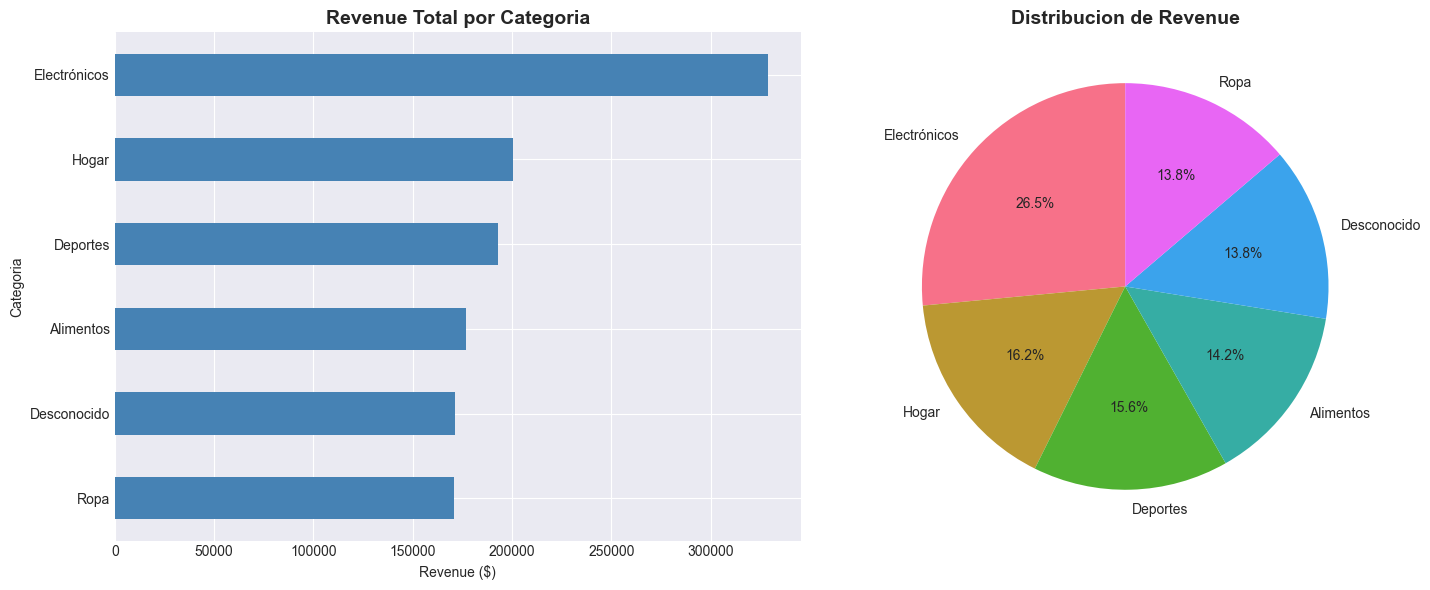

In [9]:
# Gráfico de revenue por categoría
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ventas_categoria['Revenue_Total'].sort_values().plot(
    kind='barh', ax=axes[0], color='steelblue'
)
axes[0].set_title('Revenue Total por Categoria', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Revenue ($)')
axes[0].set_ylabel('Categoria')

ventas_categoria['Revenue_Total'].plot(
    kind='pie', ax=axes[1], autopct='%1.1f%%', startangle=90
)
axes[1].set_title('Distribucion de Revenue', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## 6. Análisis de Clientes

In [10]:
# Top 10 clientes
clientes_stats = df.groupby('Cliente_ID').agg({
    'Precio_Total': ['sum', 'mean', 'count']
}).round(2)

clientes_stats.columns = ['Total_Gastado', 'Ticket_Promedio', 'Num_Compras']
top_clientes = clientes_stats.nlargest(10, 'Total_Gastado')

print("TOP 10 CLIENTES")
print("="*60)
top_clientes

TOP 10 CLIENTES


,Total_Gastado,Ticket_Promedio,Num_Compras
Cliente_ID,,,
293,14460.67,1314.61,11
59,14001.65,2000.24,7
9,13682.54,2280.42,6
89,12544.55,2090.76,6
199,12461.07,3115.27,4
291,11491.11,1915.18,6
289,11384.23,1626.32,7
148,11071.52,2214.30,5
282,11071.37,1845.23,6


## 7. Conclusiones

### Hallazgos Principales:
1. Revenue total generado
2. Categoría líder en ventas
3. Clientes de alto valor identificados

### Recomendaciones:
- Enfocarse en categorías más rentables
- Programas de fidelización para top clientes
- Análisis predictivo como siguiente paso